# Как бенчмарк оценивает работу ИИ-агента и как наша модель предсказывает неудачу

**ИИ-агент** — программа на основе языковой модели, которая сама исправляет ошибку в чужом коде: читает файлы,
запускает команды, правит код и в конце отправляет исправление. **Бенчмарк SWE-bench Verified** — 500 настоящих
ошибок из открытых проектов на Python; для каждой есть скрытые тесты, которые решают, исправлена ли ошибка.
**Прогон** — одна попытка одного агента на одной задаче; **траектория** — записанные шаги этой попытки.

Наша модель смотрит только на траекторию (какие шаги агент делал и в каком порядке) и оценивает **риск** —
вероятность того, что отправленное исправление тесты не пройдёт.

> **Важно.** Сам бенчмарк в Colab не запускается: для проверки нужен Docker — отдельная виртуальная среда для каждой
> задачи. Этот ноутбук показывает **сохранённые результаты настоящей проверки** (файлы `report.json`, полученные
> на компьютере автора), а также траектории открытого рейтинга и наших собственных прогонов.

Запуск: *Runtime → Run all* на чистом рантайме, около 1–2 минут. Ключи API, вызовы языковых моделей и Docker не нужны;
все случайные операции — с `seed = 42`, повторный запуск даёт те же числа.

## 0. Подготовка

Ставится scikit-learn закреплённой версии (от неё зависят числа модели), остальное берётся из Colab. Файлы скачиваются
из репозитория по прямым ссылкам, привязанным к одному коммиту, — поэтому данные не меняются от запуска к запуску;
контрольная сумма SHA256 каждого файла сверяется.

In [1]:
%pip install -q scikit-learn==1.9.1

Note: you may need to restart the kernel to use updated packages.


In [2]:
import hashlib, json, math, os, sys, time, urllib.error, urllib.request
from pathlib import Path

T0 = time.time()
SEED = 42
REPO = "Kiruha667/diss"
DATA_REF = "caf70577556af8216c48f44937b32528482925dc"  # commit of the data files
# VISUAL_DEMO_BASE_URL overrides the location (used for the local test run)
BASE_URL = os.environ.get("VISUAL_DEMO_BASE_URL", f"https://raw.githubusercontent.com/{REPO}/{DATA_REF}")
EXPECTED_SHA256 = {
    "data/demo/runs.parquet": "7b5aa9e487d6f397ec99ab1609557373621e0b639e844556b917d575339d785c",
    "own_data/runs_own.parquet": "4edb2d283a56b809dd000f3aa9140a829205dd54638758f6aca0489969fb0603",
    "own_data/steps_own.parquet": "f1e22e746380d1d46fb854bd1d5117d1e1a9a5623aeb4eb585f17bf1acecacd6",
    "own_data/eval_summary.json": "5e21059f464a1f3ac679596a467e216f749a8c1cd43b771cb290d58e1d22ddee",
    "own_data/eval/own-v1.1_mini-v1.17.1_glm-4.6_pilot_r2_pylint-dev__pylint-6386/pylint-dev__pylint-6386/report.json": "637f9d692a87d4d458116f7e61a312605611ffd2debd76b6de03564ca95bb73e",
    "demo_lib/__init__.py": "ac4333b887076a649ecb421318d3132fb1205d4556abb7dce816084893e57b47",
    "demo_lib/phases.py": "e10b7ed305ce863a2f5adb48eca6a9c5d599f58173da73ae88f2fa9be0120391",
    "demo_lib/features.py": "6ba5908feda4c022b05fa5698d882919b2d53c866e3d45db40158a466b16bd94"
}
DATA = Path("visual_demo_data")


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def download(url, path, attempts=3):
    for i in range(attempts):
        try:
            with urllib.request.urlopen(url, timeout=120) as r, open(path, "wb") as fh:
                while chunk := r.read(1 << 20):
                    fh.write(chunk)
            return
        except urllib.error.HTTPError as e:
            raise RuntimeError(f"cannot download {url} (HTTP {e.code}): the repository must be public") from None
        except OSError as e:
            if i == attempts - 1:
                raise
            print(f"retry {i + 1} for {url}: {e}")
            time.sleep(3)


for rel, expected in EXPECTED_SHA256.items():
    path = DATA / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    if not path.exists() or sha256(path) != expected:
        download(f"{BASE_URL}/{rel}", path)
    got = sha256(path)
    assert got == expected, f"SHA256 mismatch for {rel}: {got}"
    print(f"{rel[:60]:60s} {path.stat().st_size / 1e6:6.2f} MB  SHA256 OK")
sys.path.insert(0, str(DATA.resolve()))  # demo_lib: the phase labelling and features of the pipeline

data/demo/runs.parquet                                         1.60 MB  SHA256 OK


own_data/runs_own.parquet                                      0.04 MB  SHA256 OK


own_data/steps_own.parquet                                     0.33 MB  SHA256 OK


own_data/eval_summary.json                                     0.02 MB  SHA256 OK


own_data/eval/own-v1.1_mini-v1.17.1_glm-4.6_pilot_r2_pylint-   0.00 MB  SHA256 OK


demo_lib/__init__.py                                           0.00 MB  SHA256 OK


demo_lib/phases.py                                             0.01 MB  SHA256 OK


demo_lib/features.py                                           0.01 MB  SHA256 OK


In [3]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from IPython.display import display
from scipy.stats import rankdata
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from demo_lib.features import FEATURES, LEN, step_phases, steps_from_frame, trajectory_features

np.random.seed(SEED)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

# colours: resolved / unresolved, phases edit / verify / other; the two models
C = {"resolved": "#2ca02c", "unresolved": "#d62728", "edit": "#ff7f0e", "verify": "#17becf", "other": "#9e9e9e"}
MODEL_COLOR = {"M_len": "#7f7f7f", "M_struct+len": "#1f4e9c"}
MODEL_NAME = {"M_len": "только длина (M_len)", "M_struct+len": "длина + структура (M_struct+len)"}
plt.rcParams.update({"figure.dpi": 100, "font.size": 10, "axes.titlesize": 11, "axes.spines.top": False,
                     "axes.spines.right": False})

runs = pd.read_parquet(DATA / "data/demo/runs.parquet")
own_all = pd.read_parquet(DATA / "own_data/runs_own.parquet")
steps_own = pd.read_parquet(DATA / "own_data/steps_own.parquet")
evals = pd.DataFrame(json.loads((DATA / "own_data/eval_summary.json").read_text(encoding="utf-8")))

# own runs in the analysis: protocol >= 1.1, without psf/requests (excluded by protocol 1.2: tests use a web service)
own = own_all[(own_all.protocol_version != "1.0") & ~own_all.task_id.str.startswith("psf__requests")].copy()
own["run"] = own.run_id.str.split("/").str[0]
own["short"] = own.task_id.str.split("__").str[1]
own = own.sort_values(["task_id", "repeat_idx"]).reset_index(drop=True)
own["label"] = own.short + ", попытка " + own.repeat_idx.astype(str)
ev_own = own.merge(evals.rename(columns={"run_id": "run", "resolved": "resolved_report"}), on=["run", "task_id"])
assert len(ev_own) == len(own) and (ev_own.resolved == ev_own.resolved_report).all()
print(f"open leaderboard: {len(runs)} runs | own runs: {len(own)} on {own.task_id.nunique()} tasks, "
      f"resolved {int(own.resolved.sum())} | report.json summaries: {len(evals)}")

python 3.12.14 | numpy 2.5.4 | pandas 3.1.0 | scikit-learn 1.9.1 | matplotlib 3.11.2
open leaderboard: 7975 runs | own runs: 20 on 12 tasks, resolved 13 | report.json summaries: 89


## 1. Как бенчмарк выставляет оценку

У каждой задачи два набора скрытых тестов:

- **FAIL_TO_PASS** — тесты, которые до исправления падают. После правки агента они **должны начать проходить**:
  ошибка исправлена.
- **PASS_TO_PASS** — тесты, которые проходили и раньше. После правки они **не должны сломаться**: ничего не испорчено.

```
исправление агента ──► применить к коду ──► запустить тесты
                                              │
          все FAIL_TO_PASS прошли?  ── да ──┐ │
          все PASS_TO_PASS прошли?  ── да ──┴─┴──► РЕШЕНО
          хотя бы один тест упал или исправление не применилось ──► НЕ РЕШЕНО
```

Задача решена, **только если выполнено и то и другое**. Частичного зачёта нет: один упавший тест из сотен —
и задача не решена.

Наши 20 прогонов, по строке на прогон: слева — тесты, которые должны были начать проходить, справа — тесты, которые не
должны были сломаться (попытки одной задачи нумеруются с нуля). Во всех 7 нерешённых прогонах ошибка исправлена не до
конца (красное слева), а старое сломано лишь однажды — django-11433, 1 тест из 142. Частичного зачёта нет: у
django-14140 прошли 2 теста из 4, и задача не решена.

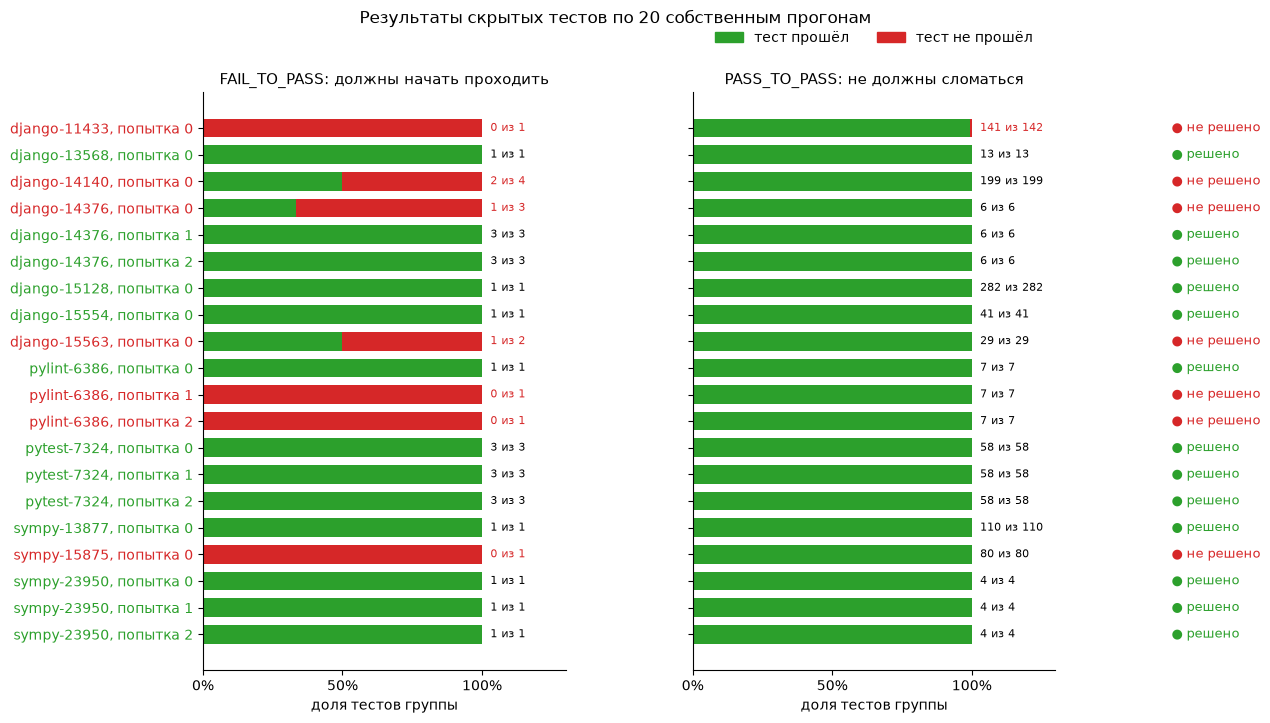

In [4]:
d = ev_own.iloc[::-1].reset_index(drop=True)  # first task on top
yy = np.arange(len(d))
fig, axes = plt.subplots(1, 2, figsize=(11, 7.5), sharey=True, gridspec_kw={"wspace": 0.35})
panels = [("f2p", "FAIL_TO_PASS: должны начать проходить"), ("p2p", "PASS_TO_PASS: не должны сломаться")]
for ax, (kind, title) in zip(axes, panels):
    ok, bad = d[f"{kind}_pass"].to_numpy(), d[f"{kind}_fail"].to_numpy()
    tot = np.maximum(ok + bad, 1)
    ax.barh(yy, ok / tot, color=C["resolved"], height=0.7)
    ax.barh(yy, bad / tot, left=ok / tot, color=C["unresolved"], height=0.7)
    for y0, o, b in zip(yy, ok, bad):
        ax.text(1.03, y0, f"{o} из {o + b}" if o + b else "нет тестов", va="center", fontsize=8,
                color=C["unresolved"] if b else "black")
    ax.set_xlim(0, 1.3)
    ax.set_xticks([0, 0.5, 1], ["0%", "50%", "100%"])
    ax.set_xlabel("доля тестов группы")
    ax.set_title(title)
axes[0].set_yticks(yy, d.label)
for tick, res in zip(axes[0].get_yticklabels(), d.resolved):
    tick.set_color(C["resolved"] if res else C["unresolved"])
for y0, res in zip(yy, d.resolved):
    axes[1].text(1.32, y0, "● решено" if res else "● не решено", va="center", fontsize=9,
                 color=C["resolved"] if res else C["unresolved"], transform=axes[1].get_yaxis_transform())
axes[1].legend(handles=[Patch(color=C["resolved"], label="тест прошёл"), Patch(color=C["unresolved"], label="тест не прошёл")],
               loc="lower center", bbox_to_anchor=(0.5, 1.06), ncol=2, frameon=False)
fig.suptitle("Результаты скрытых тестов по 20 собственным прогонам", y=0.99, fontsize=12)
plt.show()

Один прогон крупно — задача pylint-dev__pylint-6386, попытка 2, прямо из файла `report.json`, который пишет бенчмарк.
Исправление применилось, все 7 старых тестов прошли, но единственный тест FAIL_TO_PASS (`test_short_verbose`) по-прежнему
падает — значит, ошибка не исправлена и задача не решена.

In [5]:
PYLINT_REPORT = "own_data/eval/own-v1.1_mini-v1.17.1_glm-4.6_pilot_r2_pylint-dev__pylint-6386/pylint-dev__pylint-6386/report.json"
task = "pylint-dev__pylint-6386"
rep = json.loads((DATA / PYLINT_REPORT).read_text(encoding="utf-8"))[task]
rows = [{"группа тестов": kind, "тест": t, "результат": name}
        for kind in ("FAIL_TO_PASS", "PASS_TO_PASS")
        for res, name in (("failure", "не прошёл"), ("success", "прошёл"))
        for t in rep["tests_status"][kind][res]]
tests = pd.DataFrame(rows)
print(f"прогон: {PYLINT_REPORT.split('/')[2]}")
print(f"исправление применилось: {rep['patch_successfully_applied']} | resolved (решено): {rep['resolved']}")
print("не прошли:", ", ".join(tests.loc[tests["результат"] == "не прошёл", "тест"]) or "—")
display(tests.style.apply(lambda r: [f"color: {C['unresolved']}; font-weight: bold" if r["результат"] == "не прошёл"
                                     else "" for _ in r], axis=1).hide(axis="index"))

прогон: own-v1.1_mini-v1.17.1_glm-4.6_pilot_r2_pylint-dev__pylint-6386
исправление применилось: True | resolved (решено): False
не прошли: tests/config/test_config.py::test_short_verbose


группа тестов,тест,результат
FAIL_TO_PASS,tests/config/test_config.py::test_short_verbose,не прошёл
PASS_TO_PASS,tests/config/test_config.py::test_can_read_toml_env_variable,прошёл
PASS_TO_PASS,tests/config/test_config.py::test_unknown_message_id,прошёл
PASS_TO_PASS,tests/config/test_config.py::test_unknown_option_name,прошёл
PASS_TO_PASS,tests/config/test_config.py::test_unknown_short_option_name,прошёл
PASS_TO_PASS,tests/config/test_config.py::test_unknown_confidence,прошёл
PASS_TO_PASS,tests/config/test_config.py::test_unknown_yes_no,прошёл
PASS_TO_PASS,tests/config/test_config.py::test_unknown_py_version,прошёл


Перед сбором мы проверили само окружение: подставили вместо исправления агента эталонное исправление авторов бенчмарка
(gold_pre) для каждой из 65 задач пула. Эталон прошёл тесты везде — значит, окружение исправно, и «не решено» у агента
означает ошибку агента, а не сбой проверки.

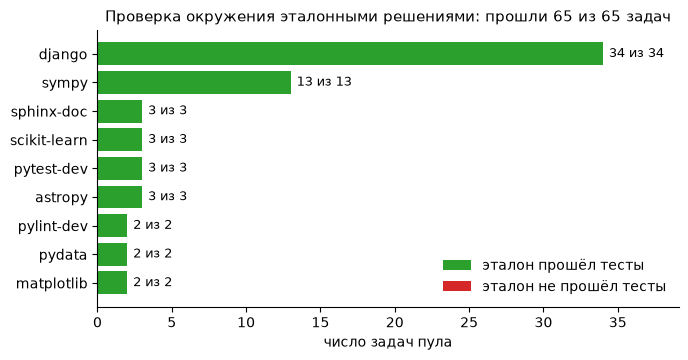

In [6]:
gold = evals[evals.run_id == "gold_pre"].copy()
gold["repo"] = gold.task_id.str.split("__").str[0]
by = gold.groupby("repo").agg(ok=("resolved", "sum"), n=("resolved", "size")).sort_values("n")
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.barh(by.index, by.ok, color=C["resolved"], label="эталон прошёл тесты")
ax.barh(by.index, by.n - by.ok, left=by.ok, color=C["unresolved"], label="эталон не прошёл тесты")
for i, (o, n) in enumerate(zip(by.ok, by.n)):
    ax.text(n + 0.4, i, f"{o} из {n}", va="center", fontsize=9)
ax.set_xlim(0, by.n.max() * 1.15)
ax.set_xlabel("число задач пула")
ax.set_title(f"Проверка окружения эталонными решениями: прошли {int(gold.resolved.sum())} из {len(gold)} задач")
ax.legend(loc="lower right", frameon=False)
plt.show()

## 2. Открытый рейтинг

Создатели SWE-bench публикуют траектории и результаты проверки разных агентов. Мы взяли режим *bash-only*:
16 связок «языковая модель + версия агента mini-SWE-agent», каждая прошла все 500 задач. Ниже — только прогоны,
где агент **отправил** исправление (`submitted == 1`): оценивать можно только отправленный результат.

Доля решённых задач у каждой из 16 связок, от худшей к лучшей. Даже лучшие решают около трёх четвертей отправленных
задач, так что неудачных прогонов много — есть что предсказывать. Связка glm-4.6 с mini-SWE-agent 1.17.1 — та же,
что в наших собственных прогонах (раздел 4), — решает 56%.

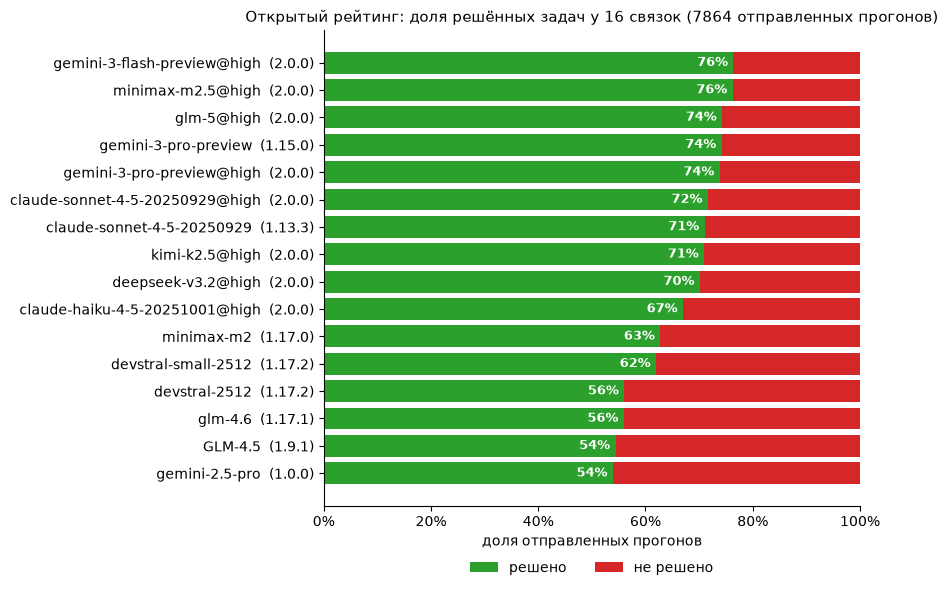

In [7]:
pop = runs[runs.submitted == 1].sort_values("run_id").reset_index(drop=True)
y = (1 - pop.resolved).to_numpy()  # 1 = not resolved: what the model predicts
lb = (pop.groupby(["model", "agent_version"]).resolved.agg(["mean", "size"]).reset_index()
      .sort_values("mean").reset_index(drop=True))
lb["name"] = lb.model + "  (" + lb.agent_version + ")"
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(lb.name, lb["mean"], color=C["resolved"], label="решено")
ax.barh(lb.name, 1 - lb["mean"], left=lb["mean"], color=C["unresolved"], label="не решено")
for i, (m, n) in enumerate(zip(lb["mean"], lb["size"])):
    ax.text(m - 0.01, i, f"{m:.0%}", va="center", ha="right", color="white", fontsize=9, fontweight="bold")
ax.set_xlim(0, 1)
ax.set_xticks(np.linspace(0, 1, 6), [f"{v:.0%}" for v in np.linspace(0, 1, 6)])
ax.set_xlabel("доля отправленных прогонов")
ax.set_title(f"Открытый рейтинг: доля решённых задач у 16 связок ({len(pop)} отправленных прогонов)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

Сколько шагов делает агент в решённых (зелёный) и нерешённых (красный) прогонах. Нерешённые в среднем длиннее
(медиана 57 шагов против 47), но распределения сильно перекрываются, так что по одной длине неудачу не угадать.
К тому же длина частично отражает не поведение агента, а сложность задачи: трудные задачи и требуют больше шагов, и
чаще остаются нерешёнными.

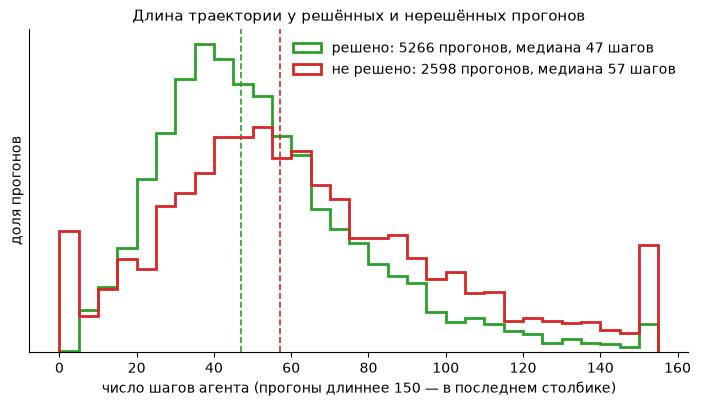

In [8]:
CAP = 150
bins = np.arange(0, CAP + 6, 5)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for val, name, color in ((1, "решено", C["resolved"]), (0, "не решено", C["unresolved"])):
    x = pop.loc[pop.resolved == val, "n_steps"]
    ax.hist(np.clip(x, 0, CAP), bins=bins, density=True, color=color, histtype="step", lw=2,
            label=f"{name}: {len(x)} прогонов, медиана {x.median():.0f} шагов")
    ax.axvline(x.median(), color=color, ls="--", lw=1.2)
ax.set_xlabel(f"число шагов агента (прогоны длиннее {CAP} — в последнем столбике)")
ax.set_ylabel("доля прогонов")
ax.set_yticks([])
ax.set_title("Длина траектории у решённых и нерешённых прогонов")
ax.legend(frameon=False)
plt.show()

## 3. Наша модель

Модель — логистическая регрессия: она складывает признаки траектории с весами и переводит сумму в вероятность
неудачи (**риск**). Две версии:

- **только длина (`M_len`)** — 4 признака: сколько шагов сделал агент, сколько из них после последней правки и т. п.;
- **длина + структура (`M_struct+len`)** — 21 признак: к длине добавлено, как агент чередовал **правки** кода,
  **проверки** (запуск тестов) и **прочие** шаги — был ли тест после последней правки, сколько раз менялась фаза и т. д.

Честная проверка: модель учится на одних задачах, а риск считается для **других** задач, которых она не видела
(разбиение на 5 частей по задачам). Сравнение — по **AUROC**: вероятность, что у случайного нерешённого прогона
риск выше, чем у случайного решённого. 0.5 — случайное угадывание, 1.0 — идеальное разделение. Код — тот же, что в
основном демо-ноутбуке.

In [9]:
MODELS = {"M_len": LEN, "M_struct+len": FEATURES}
groups = pop.task_id.to_numpy()
fold = np.full(len(pop), -1)
for k, (_, te) in enumerate(GroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(pop, y, groups)):
    fold[te] = k


def new_model():
    return make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000))


def oof_risk(cols):
    risk = np.zeros(len(pop))
    for k in range(5):
        tr, te = fold != k, fold == k
        assert not set(groups[tr]) & set(groups[te])  # no task in both train and test
        m = new_model().fit(pop.loc[tr, cols].to_numpy(float), y[tr])
        risk[te] = m.predict_proba(pop.loc[te, cols].to_numpy(float))[:, 1]
    return risk


def auroc(yy, ss):
    r = rankdata(ss)
    n1 = yy.sum()
    n0 = len(yy) - n1
    return float((r[yy == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))


risk = {name: oof_risk(cols) for name, cols in MODELS.items()}

# cluster bootstrap over tasks: the same resamples for both models
rng = np.random.default_rng(SEED)
task_rows = list(pd.Series(np.arange(len(pop))).groupby(groups).apply(np.array))
boot_idx = [np.concatenate([task_rows[i] for i in rng.integers(0, len(task_rows), len(task_rows))])
            for _ in range(1000)]
boot = {name: np.array([auroc(y[ix], r[ix]) for ix in boot_idx]) for name, r in risk.items()}

# within-task: all (unresolved, resolved) pairs of one task, pooled over tasks
pair_tasks = [ix for ix in task_rows if 0 < y[ix].sum() < len(ix)]


def pair_counts(r):
    conc, n = [], []
    for ix in pair_tasks:
        u, s = r[ix][y[ix] == 1], r[ix][y[ix] == 0]
        dd = u[:, None] - s[None, :]
        conc.append((dd > 0).sum() + 0.5 * (dd == 0).sum())
        n.append(dd.size)
    return np.array(conc), np.array(n)


within, wboot = {}, {}
rng_w = np.random.default_rng(SEED)
wsamples = [rng_w.integers(0, len(pair_tasks), len(pair_tasks)) for _ in range(1000)]
for name, r in risk.items():
    c, n = pair_counts(r)
    within[name] = c.sum() / n.sum()
    wboot[name] = np.array([c[s].sum() / n[s].sum() for s in wsamples])
ci = lambda v: np.percentile(v, [2.5, 97.5])  # noqa: E731

# the numbers must equal DEMO_REPORT.md (same data, same code)
EXPECTED = {"M_len": (0.623, 0.542), "M_struct+len": (0.662, 0.640)}
for name, (a, w) in EXPECTED.items():
    got = (round(auroc(y, risk[name]), 3), round(within[name], 3))
    assert got == (a, w), f"{name}: AUROC / within-task {got}, DEMO_REPORT.md {(a, w)}"
    print(f"{name:13s} AUROC {got[0]:.3f} (все задачи), {got[1]:.3f} (внутри задач) — совпадает с DEMO_REPORT.md")

M_len         AUROC 0.623 (все задачи), 0.542 (внутри задач) — совпадает с DEMO_REPORT.md
M_struct+len  AUROC 0.662 (все задачи), 0.640 (внутри задач) — совпадает с DEMO_REPORT.md


ROC-кривая показывает, сколько неудач поймает модель (вверх) ценой ложных тревог на успешных прогонах (вправо), если
двигать порог риска. Чем выше кривая над пунктиром случайного угадывания, тем лучше; кривая модели «длина + структура»
лежит выше кривой «только длина» почти на всём протяжении.

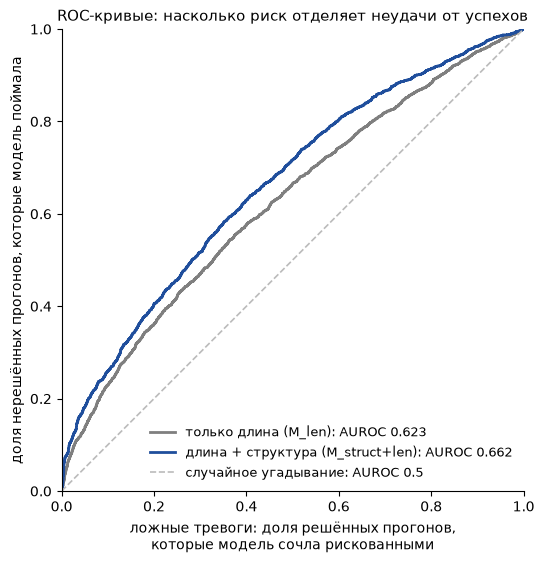

In [10]:
fig, ax = plt.subplots(figsize=(6, 6))
for name in MODELS:
    fpr, tpr, _ = roc_curve(y, risk[name])
    ax.plot(fpr, tpr, color=MODEL_COLOR[name], lw=2, label=f"{MODEL_NAME[name]}: AUROC {auroc(y, risk[name]):.3f}")
ax.plot([0, 1], [0, 1], ls="--", color="#bbbbbb", lw=1.2, label="случайное угадывание: AUROC 0.5")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect("equal")
ax.set_xlabel("ложные тревоги: доля решённых прогонов,\nкоторые модель сочла рискованными")
ax.set_ylabel("доля нерешённых прогонов, которые модель поймала")
ax.set_title("ROC-кривые: насколько риск отделяет неудачи от успехов")
ax.legend(loc="lower right", frameon=False, fontsize=9)
plt.show()

Те же модели в числах, с 95% интервалами (черта над столбиком). Слева — сравнение любых прогонов между собой; справа —
**различение внутри задачи между разными моделями**: в рейтинге каждая связка делала одну попытку на задачу, поэтому
решённый и нерешённый прогоны одной задачи всегда сделаны разными моделями. Там длина почти бесполезна (0.542), а
структура даёт 0.640 — но одно лишь знание модели даёт там 0.742 (этап E7, следующий график), то есть 0.640 в основном
отражает, какая модель работала.

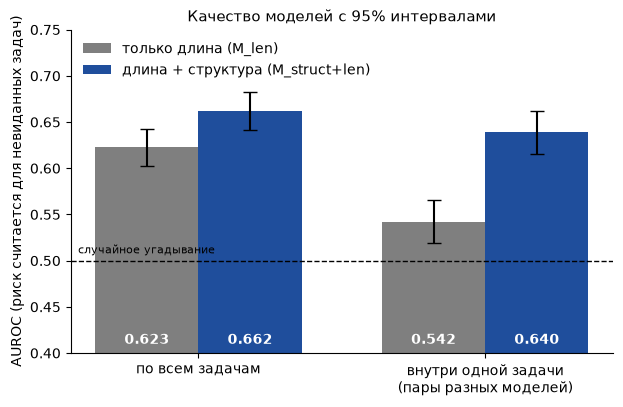

In [11]:
modes = [("по всем задачам", {m: auroc(y, risk[m]) for m in MODELS}, boot),
         ("внутри одной задачи\n(пары разных моделей)", within, wboot)]
fig, ax = plt.subplots(figsize=(7, 4.2))
w = 0.36
for j, name in enumerate(MODELS):
    vals = [v[name] for _, v, _ in modes]
    errs = np.array([[v[name] - ci(b[name])[0], ci(b[name])[1] - v[name]] for _, v, b in modes]).T
    bars = ax.bar(np.arange(2) + (j - 0.5) * w, vals, w, yerr=errs, capsize=5, color=MODEL_COLOR[name],
                  label=MODEL_NAME[name])
    for b_, v_ in zip(bars, vals):
        ax.text(b_.get_x() + b_.get_width() / 2, 0.41, f"{v_:.3f}", ha="center", color="white", fontweight="bold")
ax.axhline(0.5, color="black", lw=1, ls="--")
ax.text(-0.42, 0.505, "случайное угадывание", ha="left", va="bottom", fontsize=8)
ax.set_xticks(np.arange(2), [m for m, _, _ in modes])
ax.set_ylim(0.4, 0.75)
ax.set_ylabel("AUROC (риск считается для невиданных задач)")
ax.set_title("Качество моделей с 95% интервалами")
ax.legend(loc="upper left", frameon=False)
plt.show()

**Что стоит за 0.640.** Та же модель, которой известно только, какая связка работала (ни одного признака траектории),
различает прогоны внутри задачи лучше структуры — 0.742, а знание модели вместе со структурой дают лучший результат по
всем задачам — 0.685. Справа — только пары, где обе модели почти одинаково сильны (доля решённых задач различается
меньше чем на 3 процентных пункта): там знание модели не помогает (0.491), а структура даёт 0.544 — слабый сигнал,
предварительный: он проверяется на повторных прогонах одной модели (оговорки — `reports/E7_REPORT.md`, раздел 9).

M, M+S и пары близких по силе моделей: числа совпадают с E7_REPORT.md


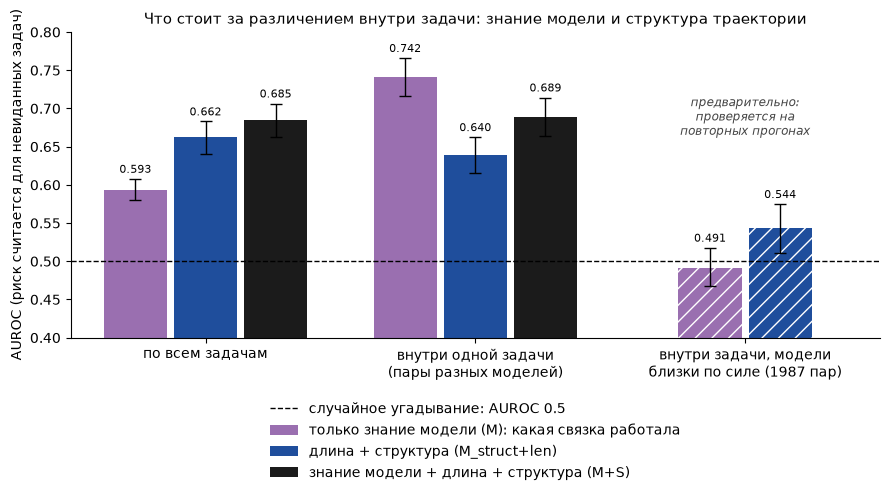

In [12]:
# E7 (reports/E7_REPORT.md): the same logistic regression on the model identity alone (M: one-hot of the 16 combos,
# not a single trajectory feature) and on model identity + the 21 features (M+S); S is M_struct+len above
combo = (pop.model + " | " + pop.agent_version).to_numpy()
COMBOS = sorted(set(combo))
MCOLS = [f"combo: {c}" for c in COMBOS]
for c, col in zip(COMBOS, MCOLS):
    pop[col] = (combo == c).astype(float)
risk7 = {"M": oof_risk(MCOLS), "S": risk["M_struct+len"], "M+S": oof_risk(MCOLS + FEATURES)}


def prec10(yy, ss):  # share of unresolved among the 10% riskiest runs
    return float(yy[np.argsort(-ss, kind="mergesort")[:math.ceil(0.10 * len(yy))]].mean())


# strength of a combo = its share of resolved runs; descriptive (computed from all labels), used only to pick pairs
strength = 1 - pd.Series(y).groupby(combo).transform("mean").to_numpy()
CLOSE = 0.03


def close_pair_counts(r):  # within-task pairs whose two combos differ in strength by less than CLOSE
    conc, n = [], []
    for ix in pair_tasks:
        u, s = ix[y[ix] == 1], ix[y[ix] == 0]
        close = np.abs(strength[u][:, None] - strength[s][None, :]) < CLOSE
        dd = r[u][:, None] - r[s][None, :]
        conc.append(((dd > 0) + 0.5 * (dd == 0))[close].sum())
        n.append(close.sum())
    return np.array(conc), np.array(n)


e7 = {}  # (pairs, model) -> (AUROC, bootstrap values); the same resamples as above
for name, r in risk7.items():
    e7[("all", name)] = (auroc(y, r), boot["M_struct+len"] if name == "S" else
                         np.array([auroc(y[ix], r[ix]) for ix in boot_idx]))
    c, n = pair_counts(r)
    e7[("within", name)] = (c.sum() / n.sum(), np.array([c[s].sum() / n[s].sum() for s in wsamples]))
    if name != "M+S":
        c, n = close_pair_counts(r)
        e7[("close", name)] = (c.sum() / n.sum(), np.array([c[s].sum() / n[s].sum() for s in wsamples]))
p10 = {name: prec10(y, r) for name, r in risk7.items()}
p10_boot = {name: np.array([prec10(y[ix], r[ix]) for ix in boot_idx]) for name, r in risk7.items()}
n_close = int(close_pair_counts(risk7["S"])[1].sum())

# the numbers must equal reports/E7_REPORT.md (sections 2 and 9)
EXPECTED_E7 = {("all", "M"): 0.593, ("within", "M"): 0.742, ("all", "M+S"): 0.685, ("within", "M+S"): 0.689,
               ("close", "S"): 0.544, ("close", "M"): 0.491}
for key, val in EXPECTED_E7.items():
    assert round(e7[key][0], 3) == val, f"{key}: {e7[key][0]:.3f}, E7_REPORT.md {val}"
assert round(p10["M+S"], 3) == 0.656 and n_close == 1987, (p10["M+S"], n_close)
print("M, M+S и пары близких по силе моделей: числа совпадают с E7_REPORT.md")

E7_COLOR = {"M": "#9a6fb0", "S": MODEL_COLOR["M_struct+len"], "M+S": "#1b1b1b"}
E7_NAME = {"M": "только знание модели (M): какая связка работала", "S": "длина + структура (M_struct+len)",
           "M+S": "знание модели + длина + структура (M+S)"}
groups7 = [("all", "по всем задачам", ["M", "S", "M+S"]),
           ("within", "внутри одной задачи\n(пары разных моделей)", ["M", "S", "M+S"]),
           ("close", f"внутри задачи, модели\nблизки по силе ({n_close} пар)", ["M", "S"])]
fig, ax = plt.subplots(figsize=(9, 5.2))
w = 0.26
for gi, (key, _, names) in enumerate(groups7):
    for j, name in enumerate(names):
        v, b = e7[(key, name)]
        lo, hi = ci(b)
        x = gi + (j - (len(names) - 1) / 2) * w
        ax.bar(x, v, w * 0.9, color=E7_COLOR[name], hatch="//" if key == "close" else None, edgecolor="white",
               lw=0, label=E7_NAME[name] if gi == 0 else None)
        ax.errorbar(x, v, yerr=[[v - lo], [hi - v]], color="black", capsize=4, lw=1)
        ax.text(x, hi + 0.008, f"{v:.3f}", ha="center", fontsize=8)
ax.text(2, 0.66, "предварительно:\nпроверяется на\nповторных прогонах", ha="center", va="bottom", fontsize=8.5,
        style="italic", color="#444444")
ax.axhline(0.5, color="black", lw=1, ls="--", label="случайное угадывание: AUROC 0.5")
ax.set_xticks(np.arange(len(groups7)), [g[1] for g in groups7])
ax.set_xlim(-0.5, len(groups7) - 0.5)
ax.set_ylim(0.4, 0.8)
ax.set_ylabel("AUROC (риск считается для невиданных задач)")
ax.set_title("Что стоит за различением внутри задачи: знание модели и структура траектории")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=1, frameon=False)
plt.tight_layout()
plt.show()

Какой риск модель «длина + структура» выдала решённым (зелёный) и нерешённым (красный) прогонам. У нерешённых риск в
среднем выше (медиана 0.36 против 0.28), но области сильно перекрываются: модель не выносит приговор отдельному прогону,
а упорядочивает прогоны — кого проверить первым.

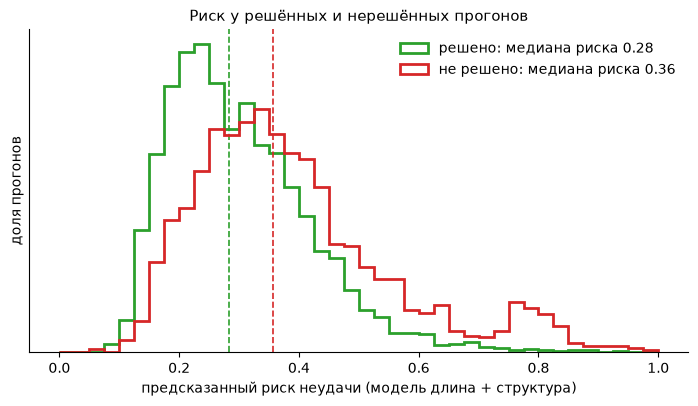

In [13]:
r = risk["M_struct+len"]
bins = np.linspace(0, 1, 41)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for val, name, color in ((0, "решено", C["resolved"]), (1, "не решено", C["unresolved"])):
    x = r[y == val]
    ax.hist(x, bins=bins, density=True, color=color, histtype="step", lw=2,
            label=f"{name}: медиана риска {np.median(x):.2f}")
    ax.axvline(np.median(x), color=color, ls="--", lw=1.2)
ax.set_xlabel("предсказанный риск неудачи (модель длина + структура)")
ax.set_ylabel("доля прогонов")
ax.set_yticks([])
ax.set_title("Риск у решённых и нерешённых прогонов")
ax.legend(frameon=False)
plt.show()

Практический смысл: если вручную проверять только самые рискованные прогоны, сколько неудач удастся найти. Проверка
5% самых рискованных находит 11% всех неудач — вдвое больше, чем случайная выборка того же размера; при 20% — 32%
против 20%.

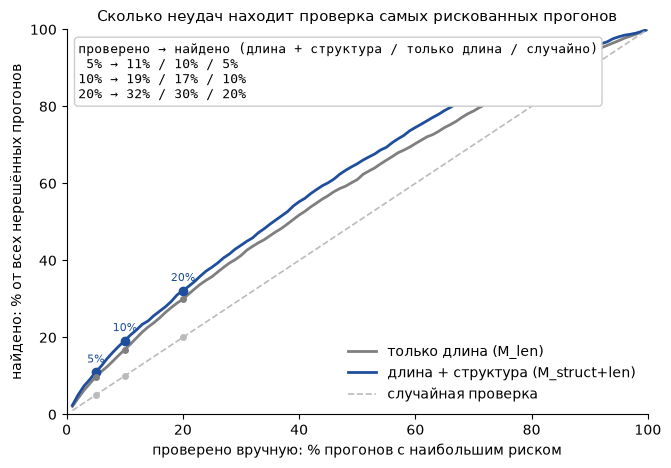

In [14]:
ks = np.arange(1, 101)
total_bad = y.sum()
order = {m: np.argsort(-risk[m], kind="mergesort") for m in MODELS}
found = {m: np.array([y[order[m][:math.ceil(k / 100 * len(y))]].sum() / total_bad for k in ks]) for m in MODELS}
fig, ax = plt.subplots(figsize=(7.5, 5))
for name in MODELS:
    ax.plot(ks, found[name] * 100, color=MODEL_COLOR[name], lw=2, label=MODEL_NAME[name])
ax.plot(ks, ks, ls="--", color="#bbbbbb", lw=1.2, label="случайная проверка")
lines = ["проверено → найдено (длина + структура / только длина / случайно)"]
for k in (5, 10, 20):
    v, v0 = found["M_struct+len"][k - 1] * 100, found["M_len"][k - 1] * 100
    ax.plot(k, v, "o", color=MODEL_COLOR["M_struct+len"])
    ax.plot(k, v0, "o", color=MODEL_COLOR["M_len"], ms=4)
    ax.plot(k, k, "o", color="#bbbbbb", ms=4)
    ax.text(k, v + 2.5, f"{k}%", ha="center", fontsize=8, color=MODEL_COLOR["M_struct+len"])
    lines.append(f"{k:>2d}% → {v:.0f}% / {v0:.0f}% / {k}%")
ax.text(2, 97, "\n".join(lines), va="top", fontsize=9, family="monospace",
        bbox={"boxstyle": "round", "facecolor": "white", "edgecolor": "#cccccc"})
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("проверено вручную: % прогонов с наибольшим риском")
ax.set_ylabel("найдено: % от всех нерешённых прогонов")
ax.set_title("Сколько неудач находит проверка самых рискованных прогонов")
ax.legend(loc="lower right", frameon=False)
plt.show()

На что смотрит модель: 10 признаков с наибольшим весом (модель обучена на всём рейтинге, признаки приведены к одному
масштабу). Риск ниже, когда агент разнообразно чередует чтение, правки и проверки, и выше, когда он долго не решается
на первую правку или делает много шагов. Похожие признаки делят вес между собой (два «шага после последней правки»
почти совпадают), поэтому веса — это связь с исходом, а не причина.

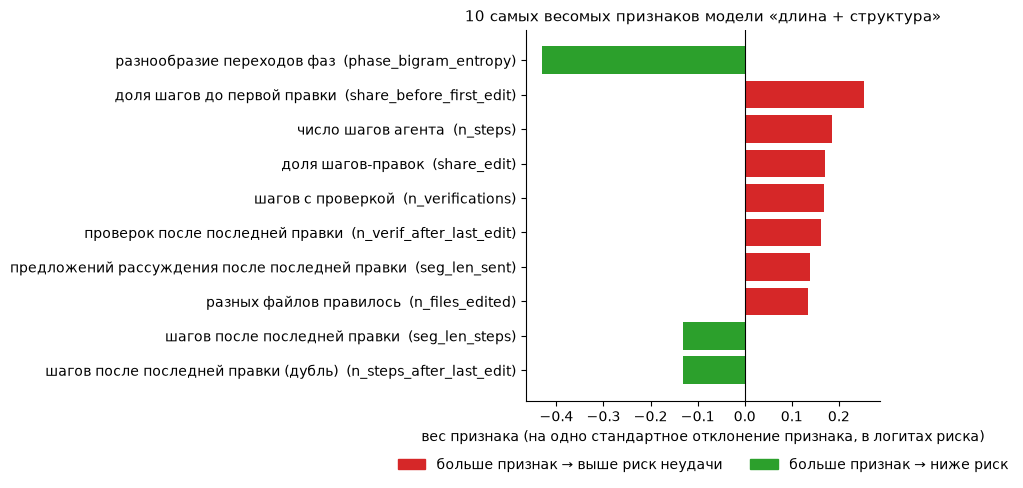

In [15]:
DESCR = {
    "n_steps": "число шагов агента", "seg_len_steps": "шагов после последней правки",
    "seg_len_sent": "предложений рассуждения после последней правки", "n_edits": "шагов с правкой",
    "has_any_verification": "была ли хоть одна проверка", "n_verifications": "шагов с проверкой",
    "verif_after_last_edit": "есть проверка после последней правки",
    "n_verif_after_last_edit": "проверок после последней правки",
    "verified_before_first_edit": "проверка до первой правки",
    "n_steps_after_last_edit": "шагов после последней правки (дубль)",
    "share_edit": "доля шагов-правок", "share_verify": "доля шагов-проверок", "share_other": "доля прочих шагов",
    "n_transitions": "смен фазы между соседними шагами", "phase_bigram_entropy": "разнообразие переходов фаз",
    "share_before_first_edit": "доля шагов до первой правки", "repeat_ratio": "доля повторов команды подряд",
    "distinct_cmd_ratio": "уникальных команд на шаг", "nonzero_rc_share": "доля команд, завершившихся ошибкой",
    "n_files_edited": "разных файлов правилось", "n_file_switches": "переключений между файлами правок"}
full = new_model().fit(pop[FEATURES].to_numpy(float), y)  # trained on the whole open leaderboard
coef = pd.Series(full[-1].coef_[0], index=FEATURES)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:10])[::-1]
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh([f"{DESCR[c]}  ({c})" for c in top.index], top,
        color=[C["unresolved"] if v > 0 else C["resolved"] for v in top])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("вес признака (на одно стандартное отклонение признака, в логитах риска)")
ax.set_title("10 самых весомых признаков модели «длина + структура»")
ax.legend(handles=[Patch(color=C["unresolved"], label="больше признак → выше риск неудачи"),
                   Patch(color=C["resolved"], label="больше признак → ниже риск")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

## 4. Собственный набор

Наши прогоны: агент mini-SWE-agent 1.17.1 с моделью GLM-4.6, задачи SWE-bench Verified, проверка — тем же
бенчмарком (раздел 1). В анализе 20 прогонов на 12 задачах: у 4 задач пилота по три попытки, у остальных пока по
одной (сбор продолжается). Задача psf/requests исключена: её тесты обращаются к внешнему веб-сервису.

Каждая строка — один прогон, каждая клетка — один шаг агента, цвет — фаза шага: правка кода, проверка (запуск
тестов) или прочее (чтение файлов, поиск). Именно из таких последовательностей модель считает свои признаки. На глаз
решённые прогоны от нерешённых не отличить — поэтому и нужна модель, которая учится на тысячах траекторий.

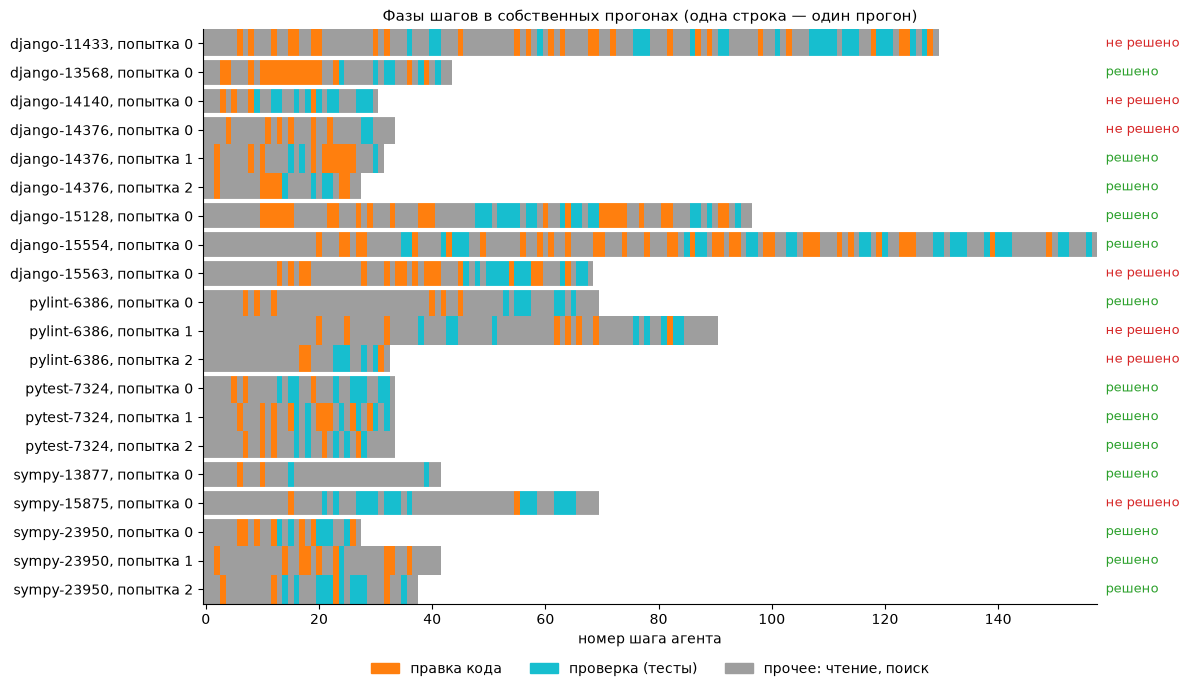

In [16]:
PHASE_CODE = {"other": 0, "edit": 1, "verify": 2}
seqs = []
for rid in own.run_id:
    g = steps_own[steps_own.run_id == rid].sort_values("step_idx")
    ph = step_phases(steps_from_frame(g))  # phases relabelled from the commands by demo_lib
    assert ph == list(g.phase), rid  # equal to the stored labels
    seqs.append([PHASE_CODE[p] for p in ph])
L = max(map(len, seqs))
mat = np.full((len(seqs), L), np.nan)
for i, s in enumerate(seqs):
    mat[i, :len(s)] = s
fig, ax = plt.subplots(figsize=(12, 7))
ax.imshow(np.ma.masked_invalid(mat), aspect="auto", interpolation="nearest",
          cmap=ListedColormap([C["other"], C["edit"], C["verify"]]), vmin=-0.5, vmax=2.5)
ax.set_yticks(np.arange(len(own)), own.label)
for i, (res, task) in enumerate(zip(own.resolved, own.task_id)):
    ax.text(L + 1, i, "решено" if res else "не решено", va="center", fontsize=9,
            color=C["resolved"] if res else C["unresolved"])
    if i and task != own.task_id[i - 1]:
        ax.axhline(i - 0.5, color="white", lw=3)
ax.set_xlim(-0.5, L - 0.5)
ax.set_xlabel("номер шага агента")
ax.set_title("Фазы шагов в собственных прогонах (одна строка — один прогон)")
ax.legend(handles=[Patch(color=C[p], label=n) for p, n in (("edit", "правка кода"), ("verify", "проверка (тесты)"),
                                                            ("other", "прочее: чтение, поиск"))],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

Риск каждого нашего прогона по модели «длина + структура», обученной на всём открытом рейтинге (наших прогонов в
обучении нет, но эти задачи там есть — их решали другие агенты). У нерешённых медиана риска 0.33, у решённых — 0.20,
но есть и исключения: самый высокий риск получил решённый прогон django-15554. На 20 прогонах это иллюстрация, а не
проверка качества.

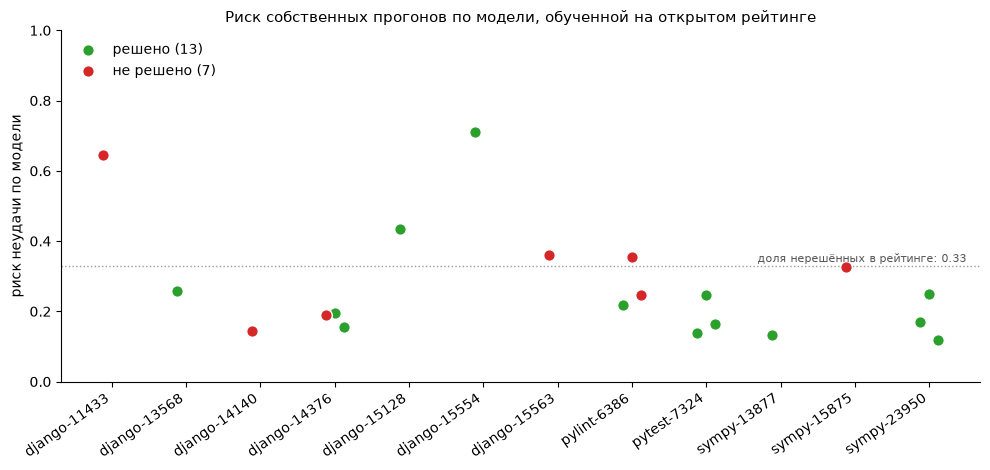

In [17]:
feat = np.array([[trajectory_features(steps_from_frame(steps_own[steps_own.run_id == rid].sort_values("step_idx")))[c]
                  for c in FEATURES] for rid in own.run_id], dtype=float)
assert np.abs(feat - own[FEATURES].to_numpy(float)).max() < 1e-9  # demo_lib = stored features
own["risk"] = full.predict_proba(feat)[:, 1]  # model trained on the whole open leaderboard (section 3f)
tasks = list(dict.fromkeys(own.task_id))
fig, ax = plt.subplots(figsize=(10, 4.8))
for res, name in ((1, "решено"), (0, "не решено")):
    s = own[own.resolved == res]
    xs = [tasks.index(t) + (k - 1) * 0.12 for t, k in zip(s.task_id, s.repeat_idx)]
    ax.scatter(xs, s.risk, s=70, color=C["resolved" if res else "unresolved"], edgecolor="white", zorder=3,
               label=f"{name} ({len(s)})")
ax.axhline(y.mean(), color="#999999", ls=":", lw=1)
ax.text(len(tasks) - 0.5, y.mean() + 0.01, f"доля нерешённых в рейтинге: {y.mean():.2f}", ha="right", fontsize=8,
        color="#555555")
ax.set_xticks(np.arange(len(tasks)), [t.split("__")[1] for t in tasks], rotation=35, ha="right")
ax.set_ylim(0, 1)
ax.set_ylabel("риск неудачи по модели")
ax.set_title("Риск собственных прогонов по модели, обученной на открытом рейтинге")
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

Самое честное сравнение — две попытки одной задачи **одной и той же моделью**, одна решённая, другая нет: одинаковы и
задача, и модель, разница только в поведении агента. У нас таких задач две (django-14376 и pylint-6386), пар — 4; линия
идёт от решённой попытки к нерешённой и должна подниматься. Это иллюстрация на четырёх парах, не статистика; в рейтинге
таких пар нет вовсе — там каждая модель делала одну попытку на задачу (раздел 3).

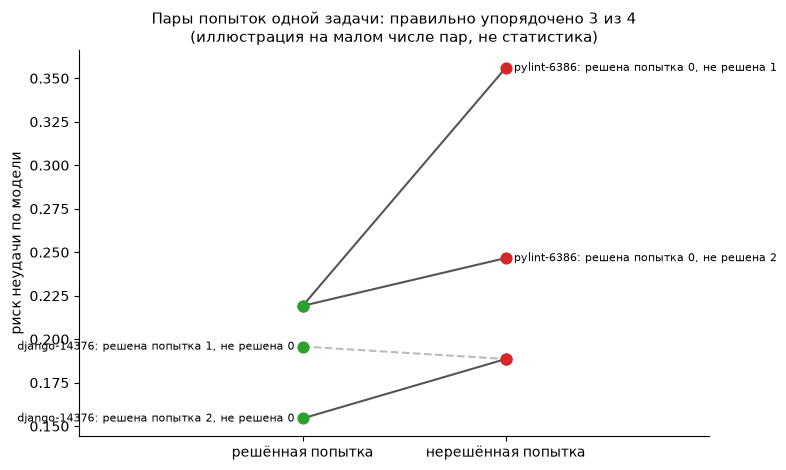

In [18]:
mixed = [t for t in tasks if own[own.task_id == t].resolved.nunique() == 2]
pairs = [(t, a, b) for t in mixed
         for a in own[(own.task_id == t) & (own.resolved == 1)].itertuples()
         for b in own[(own.task_id == t) & (own.resolved == 0)].itertuples()]
n_ok = sum(b.risk > a.risk for _, a, b in pairs)
shared = pd.Series([b.run_id for _, _, b in pairs]).value_counts()  # an unresolved run in several pairs
fig, ax = plt.subplots(figsize=(8, 4.8))
for t, a, b in pairs:
    right = b.risk > a.risk
    ax.plot([0, 1], [a.risk, b.risk], color="#555555" if right else "#bbbbbb", lw=1.5, ls="-" if right else "--")
    ax.scatter([0], [a.risk], s=60, color=C["resolved"], zorder=3)
    ax.scatter([1], [b.risk], s=60, color=C["unresolved"], zorder=3)
    label = f"{a.short}: решена попытка {a.repeat_idx}, не решена {b.repeat_idx}"
    if shared[b.run_id] > 1:  # label at the resolved end, where the points differ
        ax.text(-0.04, a.risk, label, va="center", ha="right", fontsize=8)
    else:
        ax.text(1.04, b.risk, label, va="center", fontsize=8)
ax.set_xticks([0, 1], ["решённая попытка", "нерешённая попытка"])
ax.set_xlim(-1.1, 2.0)
ax.set_ylabel("риск неудачи по модели")
ax.set_title(f"Пары попыток одной задачи: правильно упорядочено {n_ok} из {len(pairs)}\n"
             "(иллюстрация на малом числе пар, не статистика)")
plt.tight_layout()
plt.show()

## 5. Итог

**Главный практический результат — модель «знание модели + длина + структура» (M+S): AUROC 0.685, а среди 10% самых
рискованных прогонов не решены 65.6%** (precision@10%; в среднем по рейтингу не решена треть прогонов). Различение
внутри задачи (0.640) в основном отражает, какая модель работала; сигнал поведения сверх этого (0.544 у моделей,
близких по силе) предварительный и проверяется на повторных прогонах одной модели.

In [19]:
fmt = lambda v, b: f"{v:.3f} [{ci(b)[0]:.3f}; {ci(b)[1]:.3f}]"  # noqa: E731
rows = [
    ("Открытый рейтинг: прогонов / отправлено / задач", f"{len(runs)} / {len(pop)} / {pop.task_id.nunique()}"),
    ("Доля нерешённых среди отправленных", f"{y.mean():.3f}"),
    ("ГЛАВНОЕ. AUROC, знание модели + длина + структура (M+S): все задачи [95% ДИ]", fmt(*e7[("all", "M+S")])),
    ("ГЛАВНОЕ. precision@10%, M+S: доля нерешённых среди 10% самых рискованных [95% ДИ]",
     fmt(p10["M+S"], p10_boot["M+S"])),
]
for name in MODELS:
    rows.append((f"AUROC, {MODEL_NAME[name]}: все задачи [95% ДИ]", fmt(auroc(y, risk[name]), boot[name])))
    rows.append((f"AUROC, {MODEL_NAME[name]}: внутри задач, пары разных моделей [95% ДИ]",
                 fmt(within[name], wboot[name])))
rows += [
    ("AUROC, только знание модели (M): внутри задач, пары разных моделей [95% ДИ]", fmt(*e7[("within", "M")])),
    (f"AUROC внутри задач, модели близки по силе ({n_close} пар), предварительно: длина + структура",
     fmt(*e7[("close", "S")])),
    (f"AUROC внутри задач, модели близки по силе ({n_close} пар), предварительно: только знание модели",
     fmt(*e7[("close", "M")])),
]
for name in MODELS:
    rows.append((f"Проверка 10% самых рискованных, {MODEL_NAME[name]}: найдено нерешённых",
                 f"{found[name][9]:.0%} (случайная проверка: 10%)"))
rows += [
    ("Эталонные решения прошли тесты (gold_pre)", f"{int(gold.resolved.sum())} из {len(gold)} задач"),
    ("Собственные прогоны: всего / задач / решено", f"{len(own)} / {own.task_id.nunique()} / {int(own.resolved.sum())}"),
    ("Собственные пары внутри задачи: риск выше у нерешённой (иллюстрация)", f"{n_ok} из {len(pairs)}"),
]
summary = pd.DataFrame(rows, columns=["показатель", "значение"])
display(summary.style.hide(axis="index"))
Path("visual_demo_results.json").write_text(json.dumps(
    {"summary": dict(rows), "auroc": {m: auroc(y, risk[m]) for m in MODELS}, "within": dict(within),
     "e7": {f"{k[0]}|{k[1]}": v[0] for k, v in e7.items()}, "e7_p10": p10,
     "own_risk": own[["run_id", "resolved", "risk"]].to_dict("records"), "elapsed_s": round(time.time() - T0, 1)},
    indent=1, ensure_ascii=False, default=float), encoding="utf-8")
print(f"готово за {time.time() - T0:.0f} с (после установки scikit-learn)")

показатель,значение
Открытый рейтинг: прогонов / отправлено / задач,7975 / 7864 / 500
Доля нерешённых среди отправленных,0.330
"ГЛАВНОЕ. AUROC, знание модели + длина + структура (M+S): все задачи [95% ДИ]",0.685 [0.662; 0.706]
"ГЛАВНОЕ. precision@10%, M+S: доля нерешённых среди 10% самых рискованных [95% ДИ]",0.656 [0.604; 0.706]
"AUROC, только длина (M_len): все задачи [95% ДИ]",0.623 [0.602; 0.643]
"AUROC, только длина (M_len): внутри задач, пары разных моделей [95% ДИ]",0.542 [0.519; 0.565]
"AUROC, длина + структура (M_struct+len): все задачи [95% ДИ]",0.662 [0.641; 0.683]
"AUROC, длина + структура (M_struct+len): внутри задач, пары разных моделей [95% ДИ]",0.640 [0.615; 0.662]
"AUROC, только знание модели (M): внутри задач, пары разных моделей [95% ДИ]",0.742 [0.716; 0.766]
"AUROC внутри задач, модели близки по силе (1987 пар), предварительно: длина + структура",0.544 [0.511; 0.575]


готово за 39 с (после установки scikit-learn)
